# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Левченко Денис'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 4      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам’янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 4: Одеса, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [33]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [34]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_одеса


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [35]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()
    g = clean(getter())
    g.to_parquet(path, index=False)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return gpd.read_parquet(path)

In [36]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 163.3 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 28641 | ребер 78130


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
LIVE_P = os.path.join(OUT, 'cost_live.json')
live = {k: v for k, v in COST.items() if v['спосіб'] == 'живий запит'}
if live:
    saved = json.loads(open(LIVE_P, encoding='utf-8').read()) if os.path.exists(LIVE_P) else {}
    saved.update(live)
    with open(LIVE_P, 'w', encoding='utf-8') as f:
        json.dump(saved, f, ensure_ascii=False, indent=1)

cost = pd.DataFrame(COST).T
display(cost)

first = pd.DataFrame(json.loads(open(LIVE_P, encoding='utf-8').read())).T
speed = pd.DataFrame({
    'живий запит, с': first['секунд'].astype(float),
    'знімок, с': cost['секунд'].astype(float),
    'передано мережею тоді, МБ': first['передано_МБ'].astype(float),
    'передано зараз, МБ': cost['передано_МБ'].astype(float),
})
speed['знімок швидший, разів'] = (speed['живий запит, с'] / speed['знімок, с'].clip(lower=0.001)).round(0)
display(speed)

SPEEDUP = speed['живий запит, с'].sum() / max(speed['знімок, с'].sum(), 0.001)
MB_SAVED = speed['передано мережею тоді, МБ'].sum()
print('живий запит усіх шарів: %.0f с; читання знімка: %.2f с; знімок швидший у %.0f разів'
      % (speed['живий запит, с'].sum(), speed['знімок, с'].sum(), SPEEDUP))
print('при повторному запуску мережею не передано %.1f МБ' % MB_SAVED)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.047,0.197
heritage,знімок,895,0.0,0.254,0.065
stations,знімок,26,0.0,0.037,0.011
amenities,знімок,962,0.0,0.168,0.023
мережа walk,знімок,106771,0.0,5.246,0.145


,"живий запит, с","знімок, с","передано мережею тоді, МБ","передано зараз, МБ","знімок швидший, разів"
boundary,2.3,0.197,0.050,0.0,12.0
heritage,55.6,0.065,0.860,0.0,855.0
stations,69.5,0.011,0.020,0.0,6318.0
amenities,92.9,0.023,0.416,0.0,4039.0
мережа walk,89.3,0.145,13.196,0.0,616.0


живий запит усіх шарів: 310 с; читання знімка: 0.44 с; знімок швидший у 702 разів
при повторному запуску мережею не передано 14.5 МБ


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
tags_ok = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
has_name = heritage['name'].notna() & (heritage['name'].str.strip() != '')
cand = heritage[tags_ok & has_name].reset_index(drop=True)
dropped = heritage[tags_ok & ~has_name]

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(tags_ok.sum()))
print('з них мають name       :', len(cand))
print('відкинуто без name     :', len(dropped))
print()
print('що саме відкинуто (historic):')
print(dropped['historic'].value_counts().head(8).to_string())
print()
print('що саме відкинуто (tourism):')
print(dropped['tourism'].value_counts().head(8).to_string())

усього у шарі heritage : 895
підходять за тегами    : 895
з них мають name       : 547
відкинуто без name     : 348

що саме відкинуто (historic):
historic
heritage         163
memorial          74
yes                3
fort               3
castle             2
bicycle            2
monument           2
wayside_cross      1

що саме відкинуто (tourism):
tourism
artwork       56
attraction    37
viewpoint      6


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial     189
heritage     120
monument      19
cannon         6
synagogue      4
castle         4
yes            4
building       2
tank           1
aircraft       1

=== tourism ===
tourism
artwork       84
attraction    72
museum        42
viewpoint      5
gallery        5

типи геометрії: {'Point': 343, 'Polygon': 199, 'LineString': 5}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

import re
LANG_COLS = [c for c in cand.columns if re.fullmatch(r'name:[a-z]{2,3}', c)]
cand['wiki'] = (cand['wikidata'].notna() | cand['wikipedia'].notna()).astype(int)
cand['n_lang'] = cand[LANG_COLS].notna().sum(axis=1)
cand['museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['hist'] = cand['historic'].notna().astype(int)

WEIGHTS = {'wiki': 0.35, 'n_lang': 0.30, 'museum': 0.15, 'hist': 0.10, 'area_m2': 0.10}
cand['score'] = sum(w * cand[c].rank(pct=True) for c, w in WEIGHTS.items())

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають переклади назви: %d, максимум мов: %d' % ((cand['n_lang'] > 0).sum(), cand['n_lang'].max()))
print('музеї та галереї: %d, historic заповнений: %d' % (cand['museum'].sum(), cand['hist'].sum()))
display(cand.nlargest(10, 'score')[['name', 'historic', 'tourism', 'wiki', 'n_lang', 'area_m2', 'score']].round(3))

кандидатів   : 547
мають wiki   : 47
мають переклади назви: 533, максимум мов: 9
музеї та галереї: 47, historic заповнений: 356


,name,historic,tourism,wiki,n_lang,area_m2,score
364,Літературний музей,<NA>,museum,1,5,1382.135,0.887
363,Археологічний музей,<NA>,museum,1,6,1015.168,0.886
348,Потьомкінські сходи,yes,attraction,1,9,2824.605,0.870
511,Одеський залізничний вокзал,heritage,attraction,1,5,4826.480,0.868
515,Одеський національний художній музей,<NA>,museum,1,3,1607.662,0.864
544,Воронцовський палац,castle,<NA>,1,4,1404.100,0.858
353,Синагога Ор Самеах,synagogue,attraction,1,4,1146.947,0.856
486,Прибутковий будинок Асвадурова,heritage,<NA>,1,3,1959.270,0.841
423,Римсько-католицький костьол Успіння Пресвятої ...,church,<NA>,1,3,1448.976,0.839
366,Шахський палац,castle,attraction,1,3,1194.503,0.836


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

def keys(df):
    return set(df['element'].astype(str) + '/' + df['id'].astype(str))

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10 = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap = len(keys(top10) & keys(top_naive))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

перетин: 1 з 10


,за вашим критерієм,за площею
0,Літературний музей,Свято-успенський патріарший чоловічий монастир...
1,Археологічний музей,Ангари
2,Потьомкінські сходи,Гарматні дворики
3,Одеський залізничний вокзал,Одеський художній музей
4,Одеський національний художній музей,Одеський академічний театр музичної комедії ім...
5,Воронцовський палац,Одеський залізничний вокзал
6,Синагога Ор Самеах,Одеський національний академічний театр опери ...
7,Прибутковий будинок Асвадурова,Ангари депо
8,Римсько-католицький костьол Успіння Пресвятої ...,Пасаж Менделевичів
9,Шахський палац,Тюремний замок


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

control = gpd.GeoDataFrame(geometry=gpd.points_from_xy([30.7300, 30.7301], [46.4800, 46.4801]), crs=4326)
print('контроль функції на двох точках за ~14 м:', [(i, j, round(float(d), 1)) for i, j, d in close_pairs(control)])
print()

pairs = close_pairs(top_score)
print('пар ближче 60 м у топ-%d: %d' % (N_LARGE, len(pairs)))
for i, j, d in pairs:
    print('  %5.1f м | %s  <->  %s' % (d, top_score['name'][i], top_score['name'][j]))

gone = cand['name'].str.contains('демонтован', case=False)
print()
print('у назві позначені як демонтовані (на місці їх уже немає):', ', '.join(cand.loc[gone, 'name']))
same_wd = cand[cand['wikidata'].notna() & cand['wikidata'].duplicated(keep=False)]
print('кандидати з однаковим wikidata (той самий об\u2019єкт двічі):')
print(same_wd[['element', 'name', 'historic', 'tourism', 'wikidata']].sort_values('wikidata').to_string())

def dedupe(pool):
    removed = []
    while True:
        found = close_pairs(pool.head(N_LARGE))
        if not found:
            return pool, removed
        i, j, d = found[0]
        removed.append((pool['name'][j], pool['name'][i], d))
        pool = pool.drop(index=j).reset_index(drop=True)

pool = cand[~gone].sort_values('score', ascending=False).reset_index(drop=True)
pool, removed = dedupe(pool)

top_score = pool.head(N_LARGE).reset_index(drop=True)
top10 = top_score.head(N_SMALL)
overlap = len(keys(top10) & keys(top_naive))
print()
print('рішення: з кожної пари лишаємо об’єкт з вищим рейтингом, другий прибираємо')
for a, b, d in removed:
    print('  прибрано «%s» — %.0f м від «%s»%s' % (a, d, b, ' (лишилась інша точка з тією самою назвою)' if a in set(pool['name']) else ''))
print('після чистки пар ближче 60 м у топ-%d: %d' % (N_LARGE, len(close_pairs(top_score))))
print('перетин рейтингів після чистки: %d з %d' % (overlap, N_SMALL))
display(top10[['name', 'historic', 'tourism', 'wiki', 'n_lang', 'score']].round(3))

контроль функції на двох точках за ~14 м: [(0, 1, 13.5)]

пар ближче 60 м у топ-30: 4
   21.2 м | Одеський національний художній музей  <->  Одеський художній музей
   22.4 м | Пам'ятник засновникам Одеси (демонтований)  <->  Одеський художній музей
   25.8 м | Одеський національний художній музей  <->  Пам'ятник засновникам Одеси (демонтований)
   54.9 м | Літературний музей  <->  Археологічний музей

у назві позначені як демонтовані (на місці їх уже немає): Пам'ятник засновникам Одеси (демонтований), Олександр Суворов (демонтований)
кандидати з однаковим wikidata (той самий об’єкт двічі):
      element                                  name  historic     tourism  wikidata
4        node                   Потьомкінські сходи      <NA>   viewpoint  Q1413595
348  relation                   Потьомкінські сходи       yes  attraction  Q1413595
285      node                                 ЗіС-3  memorial        <NA>   Q266837
286      node                                 ЗіС-3  memorial     

,name,historic,tourism,wiki,n_lang,score
0,Літературний музей,<NA>,museum,1,5,0.887
1,Потьомкінські сходи,yes,attraction,1,9,0.870
2,Одеський залізничний вокзал,heritage,attraction,1,5,0.868
3,Одеський національний художній музей,<NA>,museum,1,3,0.864
4,Воронцовський палац,castle,<NA>,1,4,0.858
5,Синагога Ор Самеах,synagogue,attraction,1,4,0.856
6,Прибутковий будинок Асвадурова,heritage,<NA>,1,3,0.841
7,Римсько-католицький костьол Успіння Пресвятої ...,church,<NA>,1,3,0.839
8,Шахський палац,castle,attraction,1,3,0.836
9,Пам'ятник де Рішельє,memorial,<NA>,1,4,0.832


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 26
                   name  railway building
0         Одеса-Західна  station     <NA>
1          Одеса-Поїзна  station     <NA>
2       Одеса-Застава 2  station     <NA>
3              Шевченко     halt     <NA>
4     Одеса-Сортувальна  station     <NA>
5                  Депо     halt     <NA>
6         Одеса-Пересип  station     <NA>
7           Житомирська  station     <NA>
8            Одеса-Порт  station     <NA>
9       Одеса-Застава I  station     <NA>
10           Слобідська     halt     <NA>
11  Дальницький Переїзд     halt     <NA>


In [16]:
main = stations[stations['name'].fillna('').str.contains('Одеса-Головна')]
if (main['railway'] == 'station').any():
    main = main[main['railway'] == 'station']
station = main.head(1)
print('старт:', station['name'].iloc[0])

sp = station.to_crs(32635).geometry.representative_point().iloc[0]
d_start = pool.to_crs(32635).geometry.representative_point().distance(sp)
near_start = d_start < 100
print('об\u2019єкти рейтингу ближче 100 м до старту:',
      ', '.join('%s (%.0f м)' % (n, d) for n, d in zip(pool.loc[near_start, 'name'], d_start[near_start])) or 'немає')
near_names = ['%s — %.0f м' % (n, d) for n, d in zip(pool.loc[near_start, 'name'], d_start[near_start])]
pool, removed_more = dedupe(pool[~near_start].reset_index(drop=True))
removed += removed_more
top_score = pool.head(N_LARGE).reset_index(drop=True)
top10 = top_score.head(N_SMALL)
overlap = len(keys(top10) & keys(top_naive))
print('пар ближче 60 м у топ-%d: %d; перетин рейтингів: %d з %d' % (N_LARGE, len(close_pairs(top_score)), overlap, N_SMALL))
print('десятка для маршруту:', ', '.join(top10['name']))

старт: Одеса-Головна
об’єкти рейтингу ближче 100 м до старту: Одеський залізничний вокзал (71 м), EMS Ukraine (65 м)
пар ближче 60 м у топ-30: 0; перетин рейтингів: 1 з 10
десятка для маршруту: Літературний музей, Потьомкінські сходи, Одеський національний художній музей, Воронцовський палац, Синагога Ор Самеах, Прибутковий будинок Асвадурова, Римсько-католицький костьол Успіння Пресвятої Богородиці Діви Марії, Шахський палац, Пам'ятник де Рішельє, Одеський національний академічний театр опери та балету


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 28641 вузлів, 77263 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [37]:
def check_snap(points, ids, dist, label):
    k, uniq = len(ids), len(set(ids))
    worst = int(np.argmax(dist))
    print('%s: точок %d, різних вузлів %d' % (label, k, uniq))
    print('   точка -> вузол: медіана %.1f м, максимум %.1f м («%s»)'
          % (np.median(dist), dist[worst], points['name'].iloc[worst]))
    if uniq < k:
        same = collections.defaultdict(list)
        for name, node in zip(points['name'], ids):
            same[node].append(name)
        for node, names in same.items():
            if len(names) > 1:
                print('   злиплись на вузлі %s: %s' % (node, ' | '.join(names)))
    return uniq == k

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    off = ~np.eye(len(D), dtype=bool) & np.isfinite(D) & (E > 0)
    return float(np.median(D[off] / E[off]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 11
   точка -> вузол: медіана 31.4 м, максимум 40.9 м («Воронцовський палац»)
матриця за 0.368 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.20


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [21]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    tour, left = [0], set(range(1, len(D)))
    while left:
        cur = tour[-1]
        nxt = min(sorted(left), key=lambda j: D[cur, j])
        tour.append(nxt)
        left.remove(nxt)
    return tour + [0]

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best, best_len = list(tour), tour_length(D, tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                new = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                L = tour_length(D, new)
                if L < best_len - 1e-9:
                    best, best_len, improved = new, L, True
    return best

In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,9279,5.35
2-opt,8807,0.00
Held-Karp (точний),8807,0.00



оптимальний порядок:
   0. СТАРТ: Одеса-Головна
   1. Прибутковий будинок Асвадурова
   2. Літературний музей
   3. Пам'ятник де Рішельє
   4. Потьомкінські сходи
   5. Воронцовський палац
   6. Шахський палац
   7. Одеський національний художній музей
   8. Одеський національний академічний театр опери та балету
   9. Римсько-католицький костьол Успіння Пресвятої Богородиці Діви Марії
  10. Синагога Ор Самеах
  11. СТАРТ: Одеса-Головна

довжина: 8.81 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
growth = pd.DataFrame({'точок': [11, 16, 21, 26, 31]})
growth['клітин'] = [2 ** (n - 1) * (n - 1) for n in growth['точок']]
growth['пам’ять, ГБ'] = growth['клітин'] * 8 / 1e9
growth['операцій'] = [2 ** (n - 1) * (n - 1) ** 2 for n in growth['точок']]
display(pd.DataFrame({
    'точок': growth['точок'],
    'клітин у таблиці': growth['клітин'].map('{:.1e}'.format),
    'пам’яті, ГБ': growth['пам’ять, ГБ'].map('{:.4g}'.format),
    'операцій': growth['операцій'].map('{:.1e}'.format),
}).set_index('точок'))
GB31 = float(growth['пам’ять, ГБ'].iloc[-1])
print('31 точка: %.1e клітин, %.0f ГБ лише на таблицю відстаней' % (growth['клітин'].iloc[-1], GB31))

,клітин у таблиці,"пам’яті, ГБ",операцій
точок,,,
11,1.0e+04,8.192e-05,1.0e+05
16,4.9e+05,0.003932,7.4e+06
21,2.1e+07,0.1678,4.2e+08
26,8.4e+08,6.711,2.1e+10
31,3.2e+10,257.7,9.7e+11


31 точка: 3.2e+10 клітин, 258 ГБ лише на таблицю відстаней


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [26]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 31
   точка -> вузол: медіана 22.5 м, максимум 46.6 м («Свято-Успенський кафедральний собор УПЦ МП»)
коефіцієнт обходу: 1.26
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    28561 м
2-opt            :    24021 м  за 0.006 с  (коротше на 15.9%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
комірок із пам’ятками: 219; половина з 547 пам’яток лежить у 34 комірках (15.5% комірок)


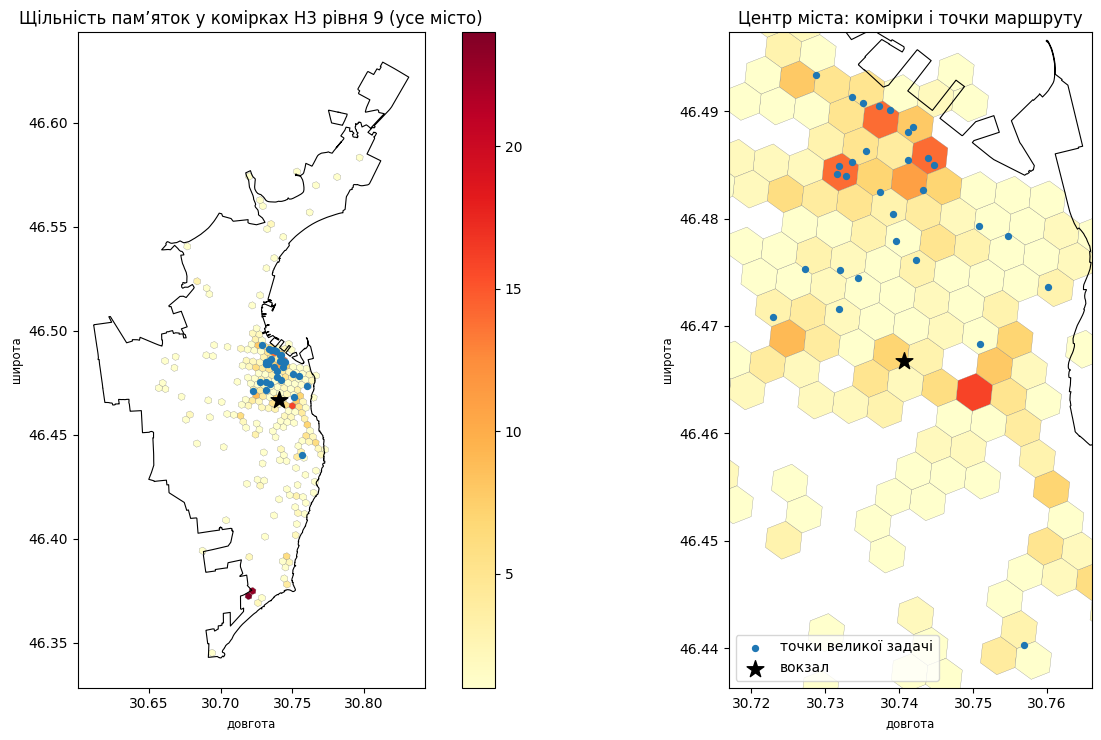

In [27]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

rp = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rp]
dens = cand['h3'].value_counts()
hexes = gpd.GeoDataFrame({'h3': dens.index, 'кількість': dens.values},
                         geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])
                                   for c in dens.index],
                         crs='EPSG:4326')
HALF = int((dens.cumsum() < len(cand) / 2).sum() + 1)
print('комірок із пам’ятками: %d; половина з %d пам’яток лежить у %d комірках (%.1f%% комірок)'
      % (len(dens), len(cand), HALF, 100 * HALF / len(dens)))

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, zoom in zip(axes, [False, True]):
    boundary.boundary.plot(ax=ax, color='black', linewidth=0.8)
    hexes.plot(ax=ax, column='кількість', cmap='YlOrRd', legend=not zoom,
               edgecolor='grey', linewidth=0.2)
    pts30.plot(ax=ax, color='#1f77b4', markersize=18, label='точки великої задачі')
    pts30.iloc[[0]].plot(ax=ax, color='black', marker='*', markersize=160, label='вокзал')
    if zoom:
        x0, y0, x1, y1 = pts30.total_bounds
        ax.set_xlim(x0 - 0.006, x1 + 0.006)
        ax.set_ylim(y0 - 0.004, y1 + 0.004)
    ax.set_aspect(1 / np.cos(np.radians(46.47)))
    ax.set_xlabel('довгота')
    ax.set_ylabel('широта')
axes[0].set_title('Щільність пам’яток у комірках H3 рівня 9 (усе місто)')
axes[1].set_title('Центр міста: комірки і точки маршруту')
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [28]:
am = amenities[['amenity', 'name', 'geometry']].copy()
am['name'] = am['name'].fillna('(без назви)')
route10 = pts10.iloc[ex10[:-1]].reset_index(drop=True)
route10['крок'] = range(len(route10))
near = gpd.sjoin_nearest(route10.to_crs(32635), am.to_crs(32635), how='left', distance_col='відстань_м')
near = near[~near.index.duplicated()]
display(near[['крок', 'name_left', 'amenity', 'name_right', 'відстань_м']]
        .rename(columns={'name_left': 'точка маршруту', 'amenity': 'тип закладу',
                         'name_right': 'найближчий заклад'}).round(1))
print('медіана відстані до найближчого закладу: %.0f м' % near['відстань_м'].median())

,крок,точка маршруту,тип закладу,найближчий заклад,відстань_м
0,0,СТАРТ: Одеса-Головна,cafe,Варенична,42.1
1,1,Прибутковий будинок Асвадурова,cafe,Дядя Миша,96.6
2,2,Літературний музей,cafe,Omega Three,106.5
3,3,Пам'ятник де Рішельє,cafe,Франс.уа,49.3
4,4,Потьомкінські сходи,toilets,(без назви),57.5
5,5,Воронцовський палац,toilets,(без назви),47.3
6,6,Шахський палац,toilets,(без назви),119.3
7,7,Одеський національний художній музей,toilets,(без назви),23.2
8,8,Одеський національний академічний театр опери ...,restaurant,Щастя,78.3
9,9,Римсько-католицький костьол Успіння Пресвятої ...,restaurant,Хаджибей,49.0


медіана відстані до найближчого закладу: 49 м


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [29]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

road10 = route_coords(ex10, ids10)
straight10 = [(float(pts10.geometry.y.iloc[i]), float(pts10.geometry.x.iloc[i])) for i in ex10]

fmap = folium.Map(location=[np.mean([c[0] for c in straight10]), np.mean([c[1] for c in straight10])],
                  zoom_start=15, tiles=BASEMAP.build_url(),
                  attr=BASEMAP.html_attribution + ' | дані: &copy; OpenStreetMap contributors, ODbL')
folium.PolyLine(road10, color='#d62728', weight=5, opacity=0.85,
                tooltip='маршрут по ребрах графа: %.2f км' % (L_opt / 1000)).add_to(fmap)
folium.PolyLine(straight10, color='#1f77b4', weight=2, dash_array='8 6',
                tooltip='прямі відрізки: %.2f км' % (tour_length(E10, ex10) / 1000)).add_to(fmap)
for step, i in enumerate(ex10[:-1]):
    folium.Marker(straight10[step], tooltip='%d. %s' % (step, pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html='<div style="background:#222;color:#fff;border-radius:50%%;'
                                           'width:22px;height:22px;text-align:center;line-height:22px;'
                                           'font:bold 12px sans-serif">%d</div>' % step)).add_to(fmap)
fmap.save('lr5_маршрут.html')
print('карту збережено: lr5_маршрут.html')
print('маршрут по ребрах: %.2f км, по прямих відрізках: %.2f км (у %.2f раза довше)'
      % (L_opt / 1000, tour_length(E10, ex10) / 1000, L_opt / tour_length(E10, ex10)))
fmap

карту збережено: lr5_маршрут.html
маршрут по ребрах: 8.81 км, по прямих відрізках: 7.13 км (у 1.23 раза довше)


Та сама карта статичним рисунком — щоб маршрут по вулицях було видно і в PDF-версії зошита.

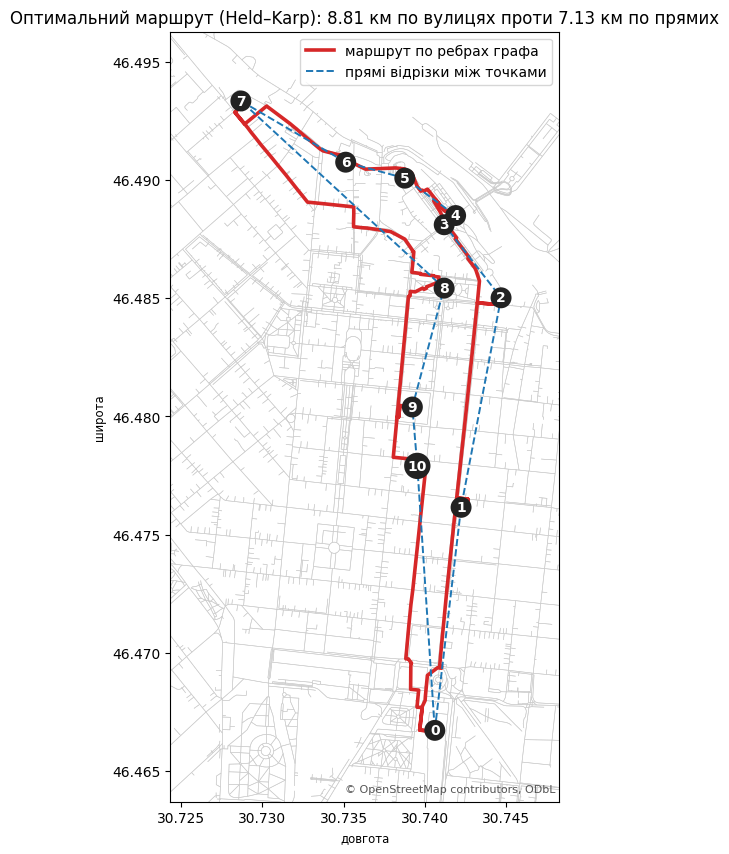

In [30]:
lat, lon = zip(*road10)
x0, x1 = min(lon) - 0.004, max(lon) + 0.004
y0, y1 = min(lat) - 0.003, max(lat) + 0.003
fig, ax = plt.subplots(figsize=(10, 10))
edges.cx[x0:x1, y0:y1].plot(ax=ax, color='#cccccc', linewidth=0.4)
ax.plot(lon, lat, color='#d62728', linewidth=2.6, label='маршрут по ребрах графа')
ax.plot([c[1] for c in straight10], [c[0] for c in straight10], '--', color='#1f77b4',
        linewidth=1.4, label='прямі відрізки між точками')
for step, i in enumerate(ex10[:-1]):
    ax.annotate(str(step), (straight10[step][1], straight10[step][0]), fontsize=10, weight='bold',
                ha='center', va='center', color='white',
                bbox=dict(boxstyle='circle,pad=0.25', fc='#222222', ec='none'))
ax.set_xlim(x0, x1)
ax.set_ylim(y0, y1)
ax.set_aspect(1 / np.cos(np.radians(np.mean(lat))))
ax.set_title('Оптимальний маршрут (Held–Karp): %.2f км по вулицях проти %.2f км по прямих'
             % (L_opt / 1000, tour_length(E10, ex10) / 1000))
ax.set_xlabel('довгота')
ax.set_ylabel('широта')
ax.legend(loc='upper right')
ax.text(0.99, 0.01, '© OpenStreetMap contributors, ODbL', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=8, color='#555555')
plt.show()

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [31]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.4 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [32]:
L_nn10, L_op10 = tour_length(D10, nn10), tour_length(D10, op10)
far_snap = [pts30['name'].iloc[i] for i in np.where(dist30 > 50)[0]]
top_hist = dropped['historic'].value_counts().head(2)
det10, det30 = detour_factor(D10, E10), detour_factor(D30, E30)
if round(det10, 2) < 1.2:
    det_text = (f'Для 10 точок це трохи нижче типового діапазону 1,2–1,6, для 30 — у ньому.')
else:
    det_text = (f'Обидва значення в типовому діапазоні пішохідної мережі 1,2–1,6; для 10 точок — на нижній межі.')
det_text += (' Причина в місті: історичний центр Одеси — прямокутна сітка кварталів, і пам’ятки десятки стоять уздовж '
             'тих самих вулиць і бульварів, тож пішки до них можна йти майже по прямій; на 30 точках з’являються '
             'пари через квартали навскіс, і коефіцієнт зростає.')
kept = set(pool['name'])
dup_text = '; '.join('«%s» за %.0f м від «%s»%s' % (a, d, b, ' — друга точка того самого об’єкта (однаковий wikidata)'
                                                     if a in kept else '') for a, b, d in removed)
REPORT = f"""
1. У шарі heritage {len(heritage)} об’єктів; усі вони підходять за об’єднанням historic або tourism з переліку {', '.join(TOURISM_OK)}. Без тегу name відкинуто {len(dropped)} — {100 * len(dropped) / int(tags_ok.sum()):.0f}% усіх кандидатів, найбільше historic={top_hist.index[0]} ({top_hist.iloc[0]}) і historic={top_hist.index[1]} ({top_hist.iloc[1]}). Залишилось {len(cand)} іменованих кандидатів. Без пояснень я б такий фільтр замовнику не віддав: він мовчки прибирає {100 * len(dropped) / int(tags_ok.sum()):.0f}% об’єктів, і серед них є справжні пам’ятки архітектури, яким у OSM просто ніхто не вписав назву.

2. Рейтинг має п’ять сигналів, кожен зведено до частки rank(pct=True): wikidata/wikipedia — {WEIGHTS['wiki']}, кількість перекладів назви — {WEIGHTS['n_lang']}, музей або галерея — {WEIGHTS['museum']}, заповнений historic — {WEIGHTS['hist']}, площа — {WEIGHTS['area_m2']}. Найбільша вага у сигналів зовнішнього визнання: статтю у Вікіпедії і переклади назви роблять люди, яким об’єкт цікавий, незалежно від OSM. Музей важить більше, ніж просто historic, бо туди можна зайти. Площа найслабша: великим буває і склад. Вікі-статтю мають {int(cand['wiki'].sum())} з {len(cand)} кандидатів, переклади назви — {int((cand['n_lang'] > 0).sum())}.

3. У першій десятці збіглося {overlap} з {N_SMALL} об’єктів за моїм критерієм і за площею. За площею в десятку потрапили, наприклад, «{top_naive['name'].iloc[1]}» і «{top_naive['name'].iloc[2]}». Обидва списки зроблено з тих самих даних без помилок. Отже, «найкращі» — це властивість обраного критерію, а не даних: відповідальність за слово «найкращі» несе аналітик, який обрав ваги.

4. Коефіцієнт обходу: {det10:.2f} для 10 точок і {det30:.2f} для 30. {det_text} Асиметрія матриці — {float(np.max(np.abs(D10 - D10.T))):.0f} м: на пішохідній мережі немає односторонніх обмежень.

5. Найближчий сусід дав {L_nn10 / 1000:.2f} км, тобто на {100 * (L_nn10 / L_opt - 1):.1f}% гірше за точний розв’язок Held–Karp ({L_opt / 1000:.2f} км). 2-opt, запущений з маршруту найближчого сусіда, дав {L_op10 / 1000:.2f} км, тобто {100 * (L_op10 / L_opt - 1):.1f}% від оптимуму{' — він знайшов саме оптимальний маршрут' if L_op10 - L_opt < 1 else ''}. На 30 точках найближчий сусід — {L_nn30 / 1000:.2f} км, 2-opt — {L_op30 / 1000:.2f} км (на {100 * (1 - L_op30 / L_nn30):.1f}% коротше, за {t_op30:.3f} с). Мене здивувало, що на 30 точках жадібний метод програє вже {100 * (L_nn30 / L_op30 - 1):.0f}% навіть відносно 2-opt: чим більше точок, тим дорожча «остання точка через усе місто».

6. Таблиця Held–Karp для 31 точки (вокзал і 30 об’єктів) має 2^30·30 ≈ 3,2·10^10 клітин; при 8 байтах на клітину це ≈ {GB31:.0f} ГБ лише для таблиці довжин (і стільки ж для таблиці попередників). Це в десятки разів більше за оперативну пам’ять будь-якого ноутбука, тож точний розв’язок неможливий через брак пам’яті, а не через брак часу.

7. Проблеми в даних і що з ними зроблено:
   • без назви — {len(dropped)} об’єктів; їх відкинуто;
   • демонтовані пам’ятники, що досі є в OSM як memorial: {', '.join(cand.loc[gone, 'name'])}; маршрут вів би до неіснуючої пам’ятки, тому їх прибрано;
   • дублікати ближче 60 м: {dup_text}; з кожної пари лишено об’єкт з вищим рейтингом;
   • вокзал є і стартом, і пам’яткою («Одеський залізничний вокзал») — у маршруті він зайняв би одне з десяти місць безплатно, тому об’єкти ближче 100 м до старту ({', '.join(near_names)}) прибрано з рейтингу; серед них «EMS Ukraine» — будинок із тегом historic=heritage, якому в OSM дали назву кур’єрської служби (опис «Кур'єрські послуги по Україні і всьому світу») — назва об’єкта неправильна;
   • у двох пам’ятних гармат «ЗіС-3» тег wikidata вказує на статтю про модель гармати, а не на сам пам’ятник, тож сигнал wiki для них хибний; у топ-{N_LARGE} вони {'не ' if not top_score['name'].eq('ЗіС-3').any() else ''}потрапили, але для рейтингу це урок: зовнішній сигнал теж треба перевіряти;
   • об’єкти далі 50 м від пішохідного графа: {', '.join(far_snap) if far_snap else 'немає'}; недосяжних пар у матрицях: {int(np.isinf(D10).sum()) + int(np.isinf(D30).sum())}.

Висновок понад завдання: пам’ятки дуже нерівномірні в просторі — половина з {len(cand)} лежить лише в {HALF} комірках H3 рівня 9 (з {len(dens)} зайнятих). Тому маршрут центром короткий, а будь-який «віддалений» об’єкт у десятці різко подовжує його. Живий запит усіх шарів тривав приблизно в {SPEEDUP:.0f} разів довше, ніж читання знімка, і повторний запуск не передав мережею {MB_SAVED:.1f} МБ — для навчального аналізу знімок є правильним проєктним рішенням.


Декларація про використання ШІ: код дописано за допомогою ШІ-помічника Claude (Anthropic) — функція fetch, фільтр кандидатів, рейтинг, чистка дублікатів, check_snap, матриці віддалей, найближчий сусід, 2-opt, H3, sjoin_nearest і карта. Перевірено самостійно: самоперевірки зошита (структура маршрутів, Held–Karp ≤ 2-opt ≤ найближчий сусід); контрольні ознаки методички (є і Point, і Polygon; різних вузлів стільки ж, скільки точок; на другому запуску всі шари — «знімок»); площі й віддалі рахуються в EPSG:32635; порядок координат перевірено картою (точки в Одесі, а не в океані); функцію пошуку близьких пар перевірено на двох точках за 14 м.
"""
print(REPORT)


1. У шарі heritage 895 об’єктів; усі вони підходять за об’єднанням historic або tourism з переліку museum, attraction, gallery, artwork, viewpoint. Без тегу name відкинуто 348 — 39% усіх кандидатів, найбільше historic=heritage (163) і historic=memorial (74). Залишилось 547 іменованих кандидатів. Без пояснень я б такий фільтр замовнику не віддав: він мовчки прибирає 39% об’єктів, і серед них є справжні пам’ятки архітектури, яким у OSM просто ніхто не вписав назву.

2. Рейтинг має п’ять сигналів, кожен зведено до частки rank(pct=True): wikidata/wikipedia — 0.35, кількість перекладів назви — 0.3, музей або галерея — 0.15, заповнений historic — 0.1, площа — 0.1. Найбільша вага у сигналів зовнішнього визнання: статтю у Вікіпедії і переклади назви роблять люди, яким об’єкт цікавий, незалежно від OSM. Музей важить більше, ніж просто historic, бо туди можна зайти. Площа найслабша: великим буває і склад. Вікі-статтю мають 47 з 547 кандидатів, переклади назви — 533.

3. У першій десятці збіглос